In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [35]:
train_dataset = pd.read_csv('train.csv', index_col=0)
test_dataset = pd.read_csv('test.csv', index_col=0)

In [ ]:
train_dataset['TARGET'] = train_dataset['TARGET'].apply(lambda x: int(x) if x.isdigit() else ord(x) - 87)
test_dataset['TARGET'] = test_dataset['TARGET'].apply(lambda x: int(x) if x.isdigit() else ord(x) - 87)

# Y = tf.keras.utils.to_categorical(train_dataset['TARGET'].values, num_classes=36)
print(len(train_dataset['TARGET'].unique()))
Y = train_dataset['TARGET']
x = StandardScaler().fit_transform(train_dataset.iloc[:, 0:63].values)

test_x = StandardScaler().fit_transform(test_dataset.iloc[:, 0:63].values)
# test_y = tf.keras.utils.to_categorical(test_dataset['TARGET'].values, num_classes=36)
test_y = test_dataset['TARGET']

train_x, validation_x, train_y, validation_y = train_test_split(x, Y, test_size=0.2, random_state=0)

36


In [39]:
# data_augmentation = tf.keras.models.Sequential([
#     tf.keras.layers.RandomRotation(.1),
#     tf.keras.layers.RandomZoom(0.1)
# ])

model = tf.keras.models.Sequential([
    tf.keras.layers.Reshape((7, 9, 1), input_shape=(63,)),
    # data_augmentation,
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.AveragePooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.AveragePooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    # tf.keras.layers.BatchNormalization(),
    # tf.keras.layers.AveragePooling2D((2, 2)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.1),
    tf.keras.layers.Dense(36, activation='softmax')
])

# model.summary()

model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
history = model.fit(train_x, train_y, epochs=12, validation_data=[validation_x, validation_y], verbose=1)
model.save('recognize_gestures_test.keras')

Epoch 1/12


d:\Coding\Projects\hand gesture recognition\.venv\Lib\site-packages\keras\src\layers\reshaping\reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.2753 - loss: 2.7543 - val_accuracy: 0.0202 - val_loss: 3.5383
Epoch 2/12
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8268 - loss: 0.6867 - val_accuracy: 0.1086 - val_loss: 3.4714
Epoch 3/12
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8890 - loss: 0.3793 - val_accuracy: 0.1010 - val_loss: 3.3192
Epoch 4/12
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9201 - loss: 0.2444 - val_accuracy: 0.1591 - val_loss: 3.0527
Epoch 5/12
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9266 - loss: 0.2201 - val_accuracy: 0.3864 - val_loss: 2.5103
Epoch 6/12
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9412 - loss: 0.1785 - val_accuracy: 0.6414 - val_loss: 1.7246
Epoch 7/12
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9467 - loss: 0.1601 - val_accuracy: 0.8561 - val_loss: 0.8776
Epoch 8/12
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9438 - loss: 0.1359 - val_accuracy: 0.8990 - val_loss: 0.4083
Ep

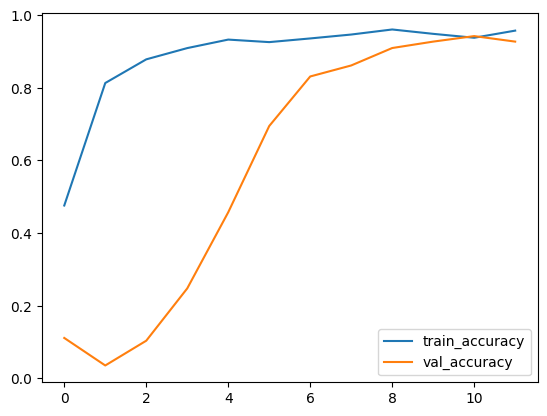

In [5]:
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.legend()
plt.show()

In [40]:
model.evaluate(test_x, test_y)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9605 - loss: 0.1629 


[0.18841269612312317, 0.9477911591529846]

In [47]:
model = tf.keras.models.load_model('recognize_gestures_test.keras')
# model.predict(test_x)
# print(test_x.shape) # (326, 63)


pred = model.predict(test_x[19:20])
print(test_x[19:20])
print(np.argmax(pred))

print(test_y[19:20])

# model.predict([test_x[0]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
[[-0.00546467  0.36890865  0.06491886 -0.2824736   0.58005782 -0.73812757
  -0.27785264  0.60610397 -0.84350286 -0.12895789  0.28711759 -0.92863885
  -0.13732868 -0.09462978 -0.98848141  0.28463608  0.76585897 -0.32898169
   0.1806561   0.4466761  -0.14607093  0.09538964 -0.53610095  0.10789212
   0.01808099 -0.85852602  0.23488719  0.27139898  1.01626266 -0.00969099
   0.36095811  0.90189071 -0.12936946  0.30096509  1.47966939  0.26605959
   0.21198398  1.28003306  0.7457997   0.12430716  0.93730854  0.35557262
   0.43860926  0.81795175  0.0093443   0.27583486  1.10550939  0.52954773
   0.00637048  0.91751014  1.07366381 -0.22037508  0.69408838  0.49660434
  -0.1978007   0.55025564  0.30652012  0.01226156  0.81992608  0.61463267
  -0.01015194  0.7855961   0.92801217]]
1
19    1
Name: TARGET, dtype: int64


In [46]:
model = tf.keras.models.load_model('recognize_gestures.keras')
# model.predict(test_x)
# print(test_x.shape) # (326, 63)


pred = np.array([
    [7.0032114e-01,  8.3986968e-01, -7.6630067e-07,  6.3386399e-01,
     7.6952708e-01,  1.2455011e-02,  5.8725369e-01,  6.5901881e-01,
     1.8499626e-02,  5.5559909e-01,  5.7630885e-01,  1.0042119e-02,
     5.5218333e-01,  5.0034350e-01,  5.0697397e-03,  6.4347076e-01,
     5.4377472e-01,  6.6968881e-02,  6.1607504e-01,  4.2358720e-01,
     4.5243949e-02,  5.8127773e-01,  4.6068189e-01,  2.5023943e-02,
     5.7463956e-01,  5.1064694e-01,  1.5522729e-02,  6.6383582e-01,
     5.3357142e-01,  4.4154800e-02,  6.3078225e-01,  4.0019971e-01,
     1.9364135e-02,  5.8891577e-01,  4.4475338e-01, -5.2619370e-04,
     5.8113569e-01,  4.9982005e-01, -5.6678103e-03,  6.8416429e-01,
     5.3434151e-01,  1.4428764e-02,  6.4232522e-01,  3.9907598e-01,
     -9.7669773e-03,  5.9111828e-01,  4.4944945e-01, -1.7730419e-02,
     5.7829463e-01,  5.1140982e-01, -1.4167691e-02,  7.0068681e-01,
     5.4169983e-01, -1.5860615e-02,  6.5045500e-01,  4.3149656e-01,
     -2.8603356e-02,  6.0154110e-01,  4.5345470e-01, -2.7738787e-02,
     5.8275437e-01,  5.0211859e-01, -2.2146072e-02]
])

pred = model.predict(pred)
print(np.argmax(pred))

print(test_y[19:20])

# model.predict([test_x[0]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
27
19    1
Name: TARGET, dtype: int64
